# Etapa 05: Qué muestras vigilar y cuánto creerle a un positivo

Esta etapa tiene dos partes que se apoyan una en la otra. En la parte A modelamos, con los mismos tres niveles de
la etapa 04, la probabilidad de que una muestra aceptada termine no conforme vista desde la recepción, y fijamos
un umbral de alerta por costo. En la parte B respondemos la pregunta con que empezó el laboratorio, qué tan
probable es que un positivo sea falso. Para eso juntamos la fiabilidad de cada ensayo (sus controles de calidad)
con el riesgo previo de cada muestra que da el clasificador de la parte A.

← Anterior: [Etapa 04: Regresión](04_regresion.ipynb)<br>[Notebook completo](Proyecto_Final.ipynb)<br>Siguiente: [Etapa 06: Agrupamiento](06_agrupamiento.ipynb) →

## Código del proyecto

La celda siguiente vuelve a crear el paquete `proyecto/` dentro de la sesión. Así el notebook funciona en Google Colab sin clonar ningún repositorio: Basta con ejecutarla una vez (*Entorno de ejecución → Ejecutar todas*). En una copia local del repositorio no reemplaza ningún archivo y la sección se puede plegar desde su título. Trae también los videos de Manim que muestra la etapa. Trae también los guiones de las etapas anteriores: Si sus resultados no están en la sesión, la etapa los vuelve a calcular en silencio antes de empezar.

In [ ]:
# Código del proyecto. Esta celda recrea en el directorio de trabajo:
#   - el paquete `proyecto/` (50 módulos) y `configuracion/mapeo_columnas.json`;
#   - los guiones de las 4 etapas previas (se reconstruyen si faltan);
#   - los videos de Manim que muestra la etapa;
# para que el notebook funcione en Google Colab sin clonar el repositorio. Todo viaja
# al final de la celda como un .tar.xz en base64 (69 archivos, 1118 kB).
# Antes de extraer se comprueba su huella SHA-256. Un archivo que ya existe con el
# mismo contenido no se toca, y uno que existe con otro contenido (una copia local
# del repositorio con cambios, por ejemplo) se conserva y se avisa; para
# reemplazarlo hay que poner SOBRESCRIBIR = True.
import base64
import hashlib
import importlib
import io
import os
import sys
import tarfile
from pathlib import Path

SOBRESCRIBIR = False


def recrear_proyecto(huella, codificado):
    datos = base64.b64decode(codificado)
    if hashlib.sha256(datos).hexdigest() != huella:
        raise ValueError("El código embebido está dañado: su SHA-256 no coincide.")
    escritos, iguales, conservados = 0, 0, []
    with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
        for miembro in archivo.getmembers():
            nombre = miembro.name
            if Path(nombre).is_absolute() or ".." in Path(nombre).parts:
                raise ValueError(f"Ruta no permitida en el archivo: {nombre}")
            contenido, destino = archivo.extractfile(miembro).read(), Path(nombre)
            if destino.exists() and destino.read_bytes() == contenido:
                iguales += 1
            elif destino.exists() and not SOBRESCRIBIR:
                conservados.append(nombre)
            else:
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(contenido)
                escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print(f"Código del proyecto: {escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto(
    huella="37a10f6d5036cdc1bd2d2f3fd5afc254684d3747a769b218184e600efe802440",
    codificado="...",
)

## Desarrollo de la etapa

In [1]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import clasificacion

iniciar_etapa("05_clasificacion_bayes")
c = clasificacion.iniciar()
mostrar(c.encabezado)

## Parte A: Clasificación

## 1. El problema, la decisión y sus costos

El costo de cada error lo fijamos antes de ver resultados porque de él depende el umbral y no al revés. Si se
alerta cuando la probabilidad pasa un umbral ${\color{#C46A2B}{t}}$, cada umbral deja unas falsas alarmas
${\color{#6B6B6B}{FP(t)}}$ y unas no conformes sin alerta ${\color{#B8423F}{FN(t)}}$, y el costo es

$$\text{Costo}({\color{#C46A2B}{t}}) = c_{FP}\,{\color{#6B6B6B}{FP(t)}} + c_{FN}\,{\color{#B8423F}{FN(t)}}
\qquad\qquad
{\color{#C46A2B}{t^{*}}} = \frac{c_{FP}}{c_{FP} + c_{FN}}$$

El segundo es el umbral teórico, el que sale si las probabilidades están bien calibradas. Como la clase positiva es
tan escasa la exactitud engaña así que medimos con tres cosas, frente a un `Dummy` que predice siempre la
proporción del entrenamiento:

a. **ROC-AUC.** La probabilidad de que una no conforme tomada al azar reciba más riesgo que una conforme. Vale 0.5
   si el modelo no ordena nada y 1 si ordena perfecto.

b. **Precisión media.** El área bajo la curva de precisión contra recall. Su referencia es la prevalencia.

c. **Brier.** El error cuadrático de la probabilidad, que premia que un 20 % de riesgo signifique de verdad unas
   veinte no conformes de cada cien.

In [2]:
clasificacion.planteamiento(c).mostrar()

## 2. Pasada didáctica: Los modelos del curso

Cada modelo usa el grupo ampliado de variables y el preprocesamiento por defecto (imputación por la mediana,
estandarización y one-hot), sin afinar nada y en los mismos bloques temporales de la etapa 04. Todo va dentro de
una tubería de scikit-learn que aprende la imputación, la escala y las categorías solo con el tramo de ajuste de
cada bloque. Así se arma la de la regresión logística:

In [3]:
from proyecto.modelos import tuberias

tuberia = tuberias.construir_tuberia("clasificacion", "logistica", c.numericas, c.categoricas)
mostrar(tuberia)   # imputar y escalar las numéricas, codificar las categóricas y ajustar el modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{f

### 2.1 Árbol de clasificación con poda por costo-complejidad

Como en la etapa 04 el árbol crece completo y después lo podamos con `ccp_alpha`, el precio que se le cobra a cada
hoja. Nos quedamos con el alfa de mayor ROC-AUC medio en los bloques. El árbol va sin escalar porque escalar no
cambia sus cortes y así los umbrales quedan en las unidades de cada variable.

In [4]:
clasificacion.poda(c).mostrar()

ccp_alpha,Hojas,ROC-AUC medio,Desv. ROC-AUC
0.000000,546,0.610,0.015
0.000038,298,0.620,0.022
0.000053,227,0.620,0.028
0.000072,148,0.620,0.034
0.000122,52,0.639,0.011
0.001655,2,0.556,0.031


### 2.2 KNN, regresión logística, árbol podado y perceptrón con sus curvas ROC

KNN da como riesgo la fracción de no conformes entre las muestras más parecidas, la logística suma señales en una
escala que después convierte en probabilidad, el árbol parte las muestras con reglas sucesivas y el perceptrón
multicapa es una red neuronal pequeña (más abajo la abrimos por dentro). La curva ROC pone en un eje la fracción
de no conformes que se alertan y en el otro la de conformes que se alertan por error, para todos los umbrales a la
vez. Si el modelo no ordenara nada sería la diagonal.

Modelo,ROC-AUC,± ROC-AUC,Precisión media,± Precisión media,Brier,± Brier,Habilidad (2 AUC − 1)
Dummy (proporción),0.5000,0.0000,0.0892,0.0131,0.0813,0.0110,0.0000
KNN,0.6337,0.0243,0.1647,0.0181,0.0808,0.0106,0.2673
Regresión logística,0.7025,0.0214,0.2539,0.0194,0.0754,0.0096,0.4049
Árbol podado,0.6386,0.0114,0.1775,0.0074,0.0849,0.0101,0.2771
Perceptrón multicapa,0.6921,0.0210,0.2354,0.0323,0.0761,0.0096,0.3843


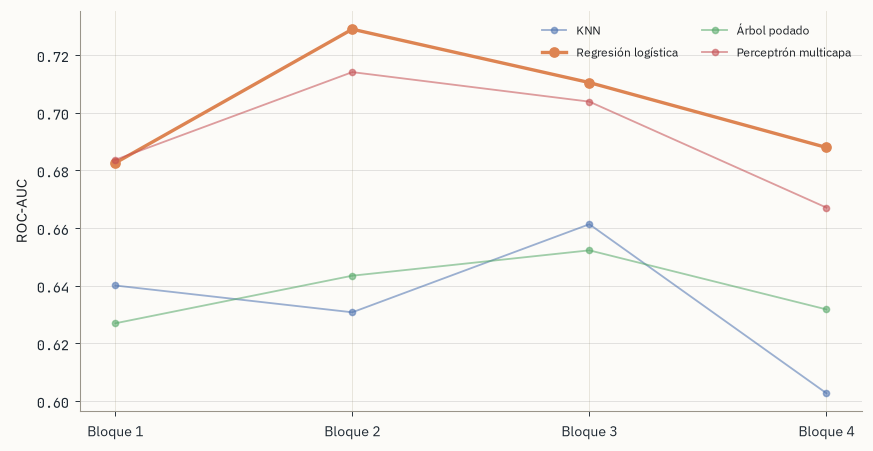

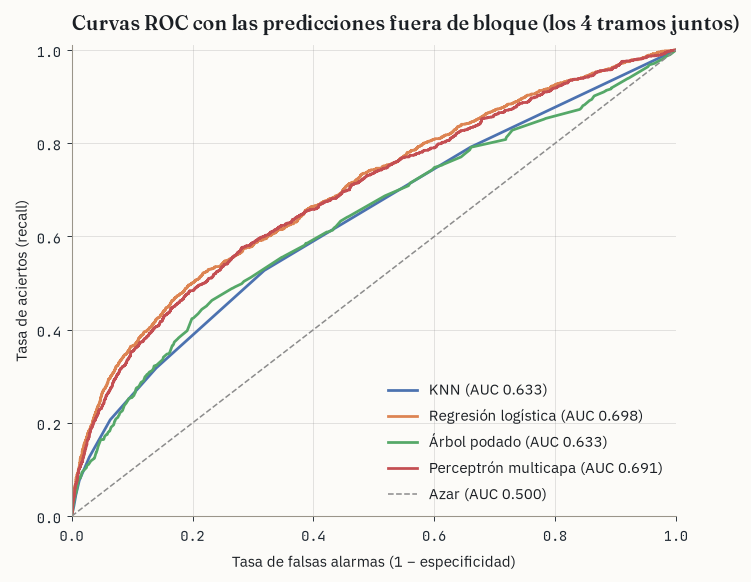

In [5]:
clasificacion.didactica(c).mostrar()

### 2.3 Qué dice la regresión logística

La regresión logística combina las variables con un peso ${\color{#6E5BA8}{\beta_j}}$ cada una y pasa la suma por
la función sigmoide $\sigma$, que la lleva al intervalo entre cero y uno:

$$p(x) = \sigma\big({\color{#6E5BA8}{\beta_0 + \beta^\top x}}\big)
= \frac{1}{1 + e^{-({\color{#6E5BA8}{\beta_0 + \beta^\top x}})}}$$

Con las numéricas estandarizadas cada coeficiente es el cambio en el logaritmo de las odds de no conformidad
cuando la variable sube una desviación estándar. Las odds son la probabilidad de no conformidad dividida entre la
de conformidad, y la exponencial del coeficiente es la razón de odds: Un 1.5 quiere decir odds un 50 % mayores.

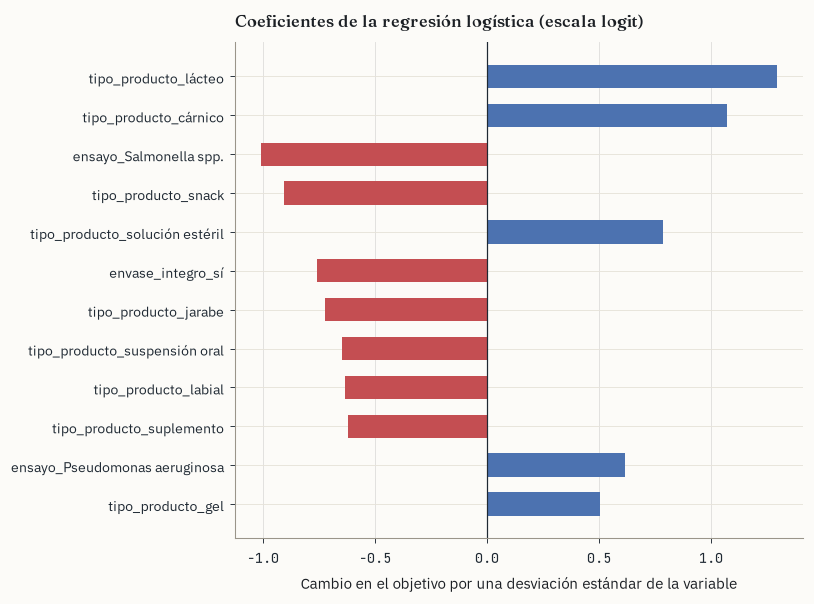

Variable,Coeficiente,Razón de odds
tipo_producto_lácteo,1.295,3.651
tipo_producto_cárnico,1.072,2.921
ensayo_Salmonella spp.,-1.011,0.364
tipo_producto_snack,-0.904,0.405
tipo_producto_solución estéril,0.783,2.188
envase_integro_sí,-0.758,0.468
tipo_producto_jarabe,-0.725,0.484
tipo_producto_suspensión oral,-0.648,0.523


In [6]:
clasificacion.logistica(c).mostrar()

### 2.4 Las reglas del árbol podado

Cada hoja es un grupo de condiciones con la fracción de no conformes de las muestras de entrenamiento que caen en
ella. Mostramos las de mayor riesgo.

In [7]:
clasificacion.reglas_arbol(c).mostrar()

Regla,Filas,Fracción de positivos
historia_producto_tasa > 0.1178 y temperatura_por_horas ≤ 298.8 y historia_producto_tasa > 0.185 y es_cuantitativo > 0.5 y ph ≤ 6.815 y temperatura_por_horas ≤ 26.31 y temperatura_por_horas > 22.47,22,0.773
historia_producto_tasa > 0.1178 y temperatura_por_horas > 298.8 y historia_producto_tasa > 0.1926,45,0.756
historia_producto_tasa > 0.1178 y temperatura_por_horas > 298.8 y historia_producto_tasa ≤ 0.1926 y historia_cliente_n_90 > 32 y volumen_ml ≤ 111,36,0.722
historia_producto_tasa > 0.1178 y temperatura_por_horas ≤ 298.8 y historia_producto_tasa > 0.185 y es_cuantitativo > 0.5 y ph ≤ 6.815 y temperatura_por_horas > 26.31 y tamano_lote > 4.5 y antiguedad_dias ≤ 1320,20,0.700
historia_producto_tasa ≤ 0.1178 y temperatura_por_horas > 293.2 y historia_producto_tasa > 0.0813 y actividad_agua > 0.9445 y horas_transporte ≤ 24.25,41,0.659
historia_producto_tasa > 0.1178 y temperatura_por_horas ≤ 298.8 y historia_producto_tasa > 0.185 y es_cuantitativo > 0.5 y ph ≤ 6.815 y temperatura_por_horas ≤ 26.31 y temperatura_por_horas ≤ 22.47 y hora_recepcion > 13.57,20,0.650


### 2.5 La red neuronal por dentro

Un **perceptrón** es la unidad más simple de una red: Multiplica cada entrada por un peso
${\color{#6E5BA8}{w}}$, suma un sesgo ${\color{#6E5BA8}{b}}$ y pasa el resultado por una función de activación
$\varphi$. El **perceptrón multicapa** (MLP) pone una capa oculta de esas unidades entre las variables y la salida,
y la salida es otra vez una logística sobre lo que dejó la capa oculta:

$$\hat y = \varphi\big({\color{#6E5BA8}{w}}^\top x + {\color{#6E5BA8}{b}}\big)
\qquad\qquad
h = \mathrm{ReLU}\big({\color{#6E5BA8}{W_1}}\, x + {\color{#6E5BA8}{b_1}}\big), \quad
\hat p = {\color{#B8423F}{\sigma}}\big({\color{#6E5BA8}{w_2}}^\top h + {\color{#6E5BA8}{b_2}}\big)$$

La activación es lo que deja a la red doblar la frontera. Sin ella las dos capas se reducirían a una sola suma
ponderada, o sea a la misma logística de la sección 2.3. Estas son las que más se usan:

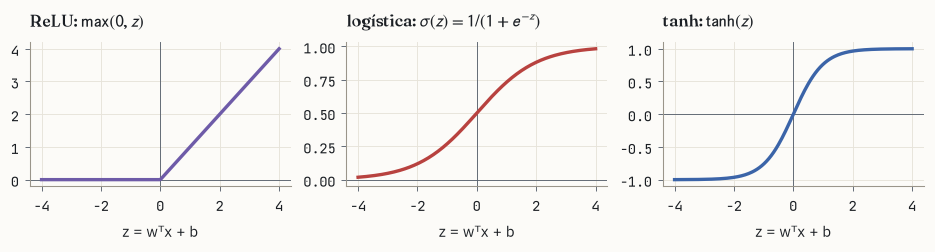

In [8]:
from proyecto.reporte import graficos_presentacion as g
from proyecto.reporte.figuras import mostrar_figura

mostrar_figura(g.figura_activaciones())   # ReLU, sigmoide y tangente hiperbólica

La red aprende con **retropropagación**. Primero mide la pérdida logarítmica, que castiga dar poca probabilidad a
lo que pasó, más una penalización ${\color{#3B64A8}{\alpha}}$ sobre el tamaño de los pesos. Después calcula con la
regla de la cadena cuánto cambia la pérdida al mover cada peso, capa por capa desde la salida hacia atrás, y mueve
cada peso un paso $\eta$ en contra de ese gradiente:

$${\color{#6E5BA8}{W_1}} \leftarrow {\color{#6E5BA8}{W_1}} - \eta\,{\color{#B8423F}{\frac{\partial L}{\partial W_1}}},
\qquad
{\color{#B8423F}{\frac{\partial L}{\partial W_1}}} = \frac{\partial L}{\partial \hat p}\;
\frac{\partial \hat p}{\partial h}\;\frac{\partial h}{\partial W_1} + 2\,{\color{#3B64A8}{\alpha}}\,{\color{#6E5BA8}{W_1}}$$

El video muestra una pasada completa con la arquitectura que usamos: La señal va hacia adelante, se mide la
pérdida, los gradientes vuelven hacia atrás y los pesos se actualizan.


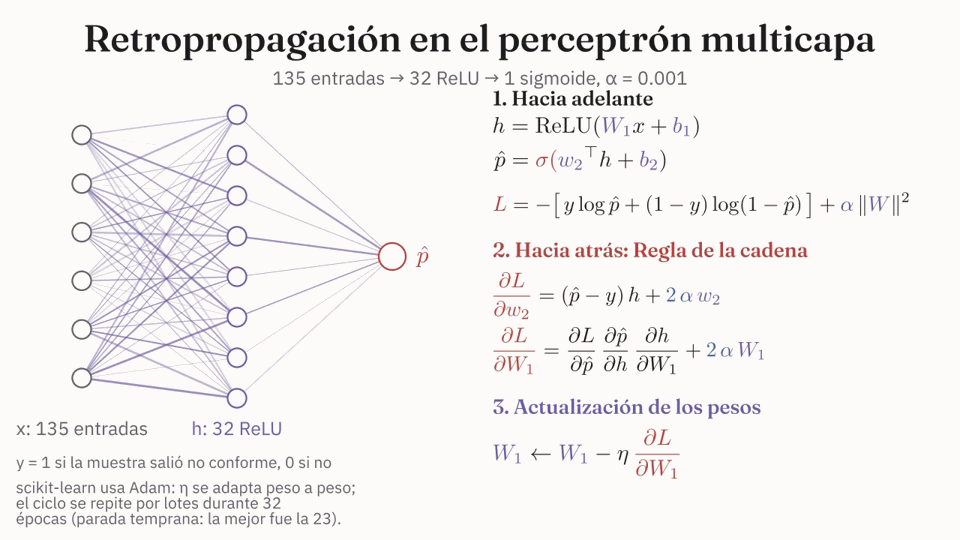

In [9]:
mostrar(g.video("red"))   # Manim: adelante, pérdida, gradientes hacia atrás y actualización

Una pasada por todo el entrenamiento se llama **época**. Para no sobreajustar usamos **parada temprana**:
scikit-learn aparta una fracción del entrenamiento, mide la exactitud ahí después de cada época y detiene el
entrenamiento cuando lleva varias épocas sin mejorar.

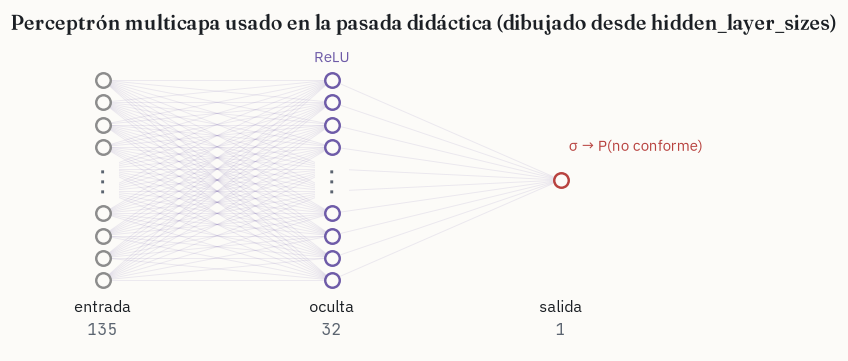

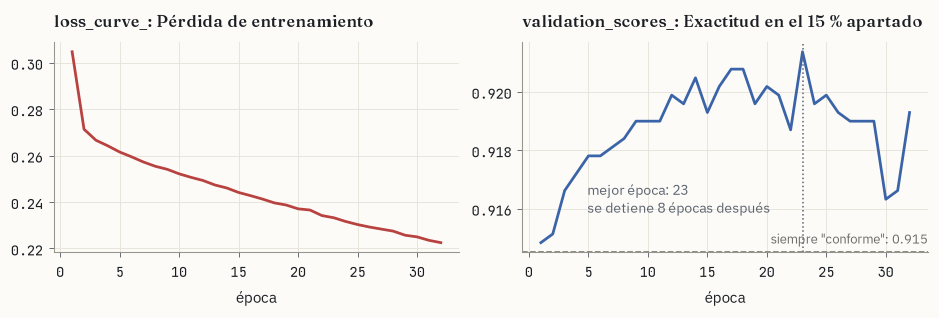

In [10]:
clasificacion.red_neuronal(c).mostrar()

La misma red entrenada época por época con `partial_fit`, midiendo en validación después de cada época. A la
derecha se ve cómo se separan (o no) las probabilidades de las conformes y de las no conformes:


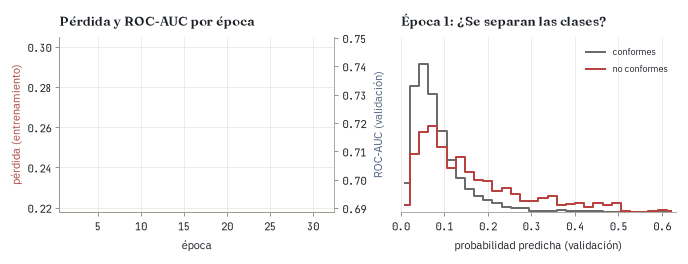
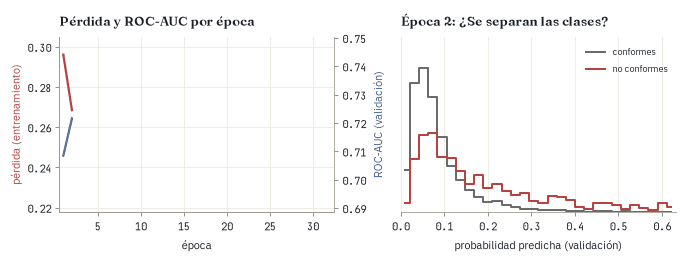
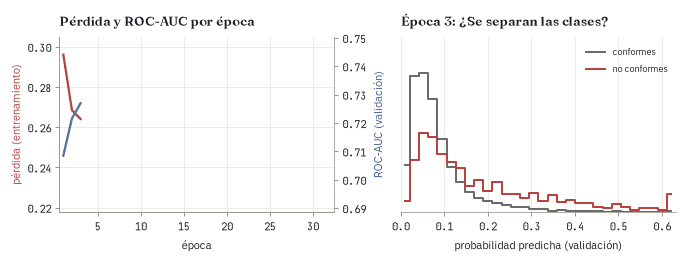
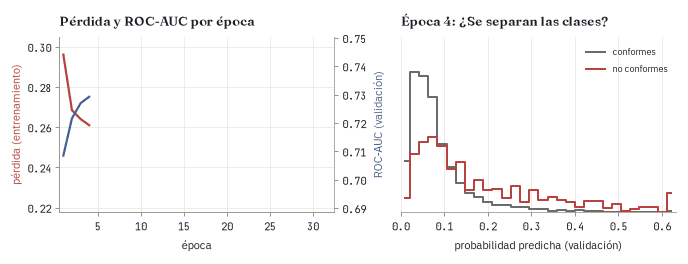
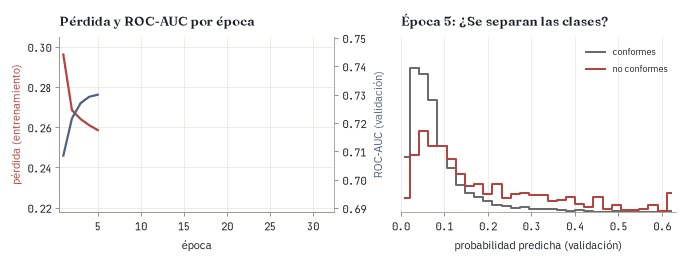
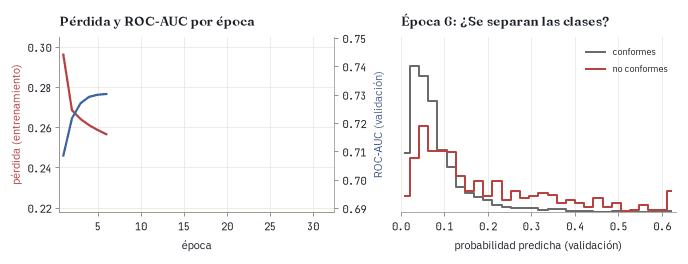
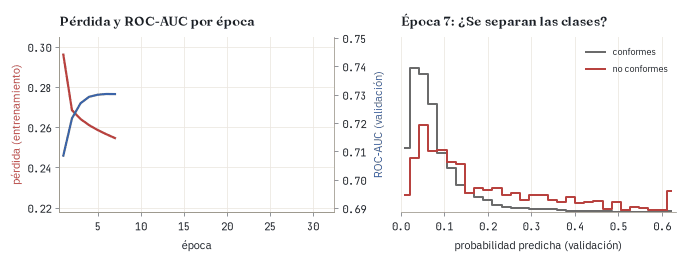
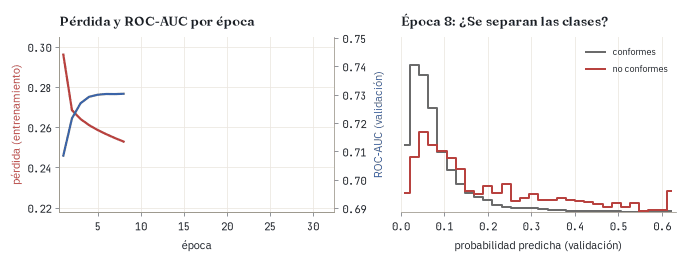
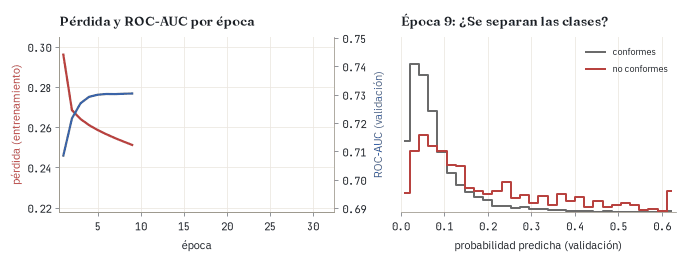
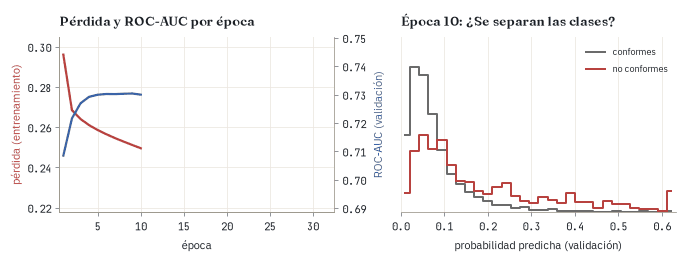
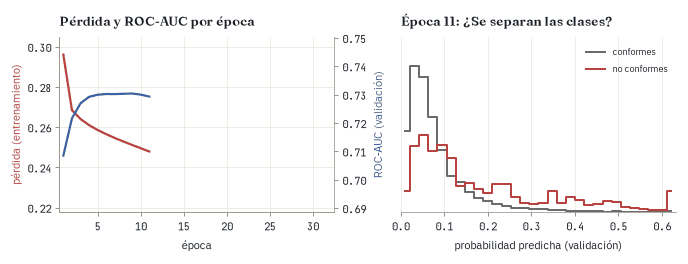
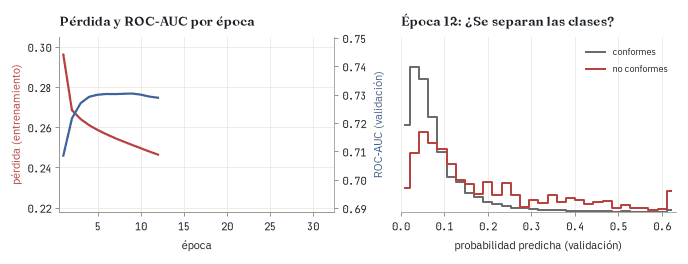
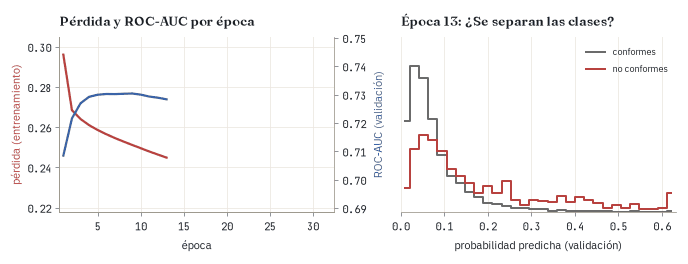
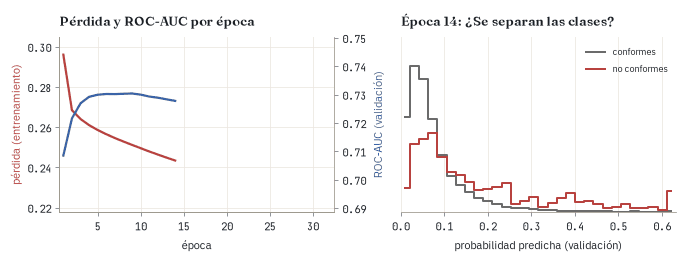
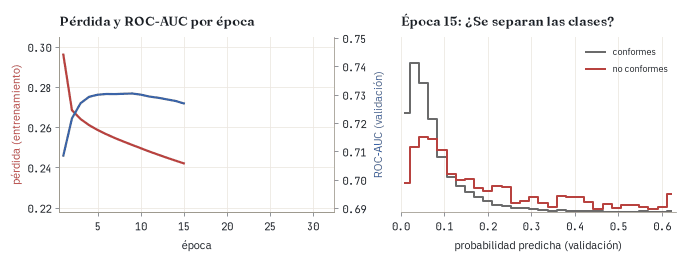
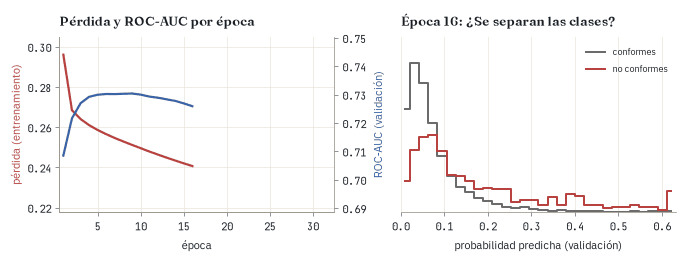
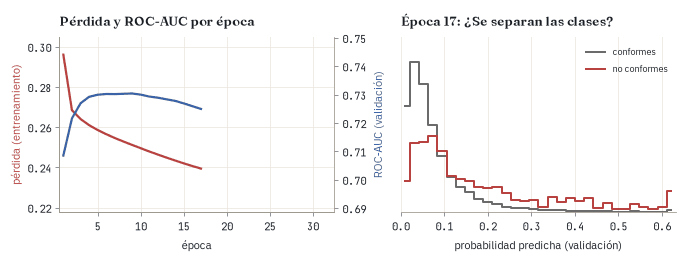
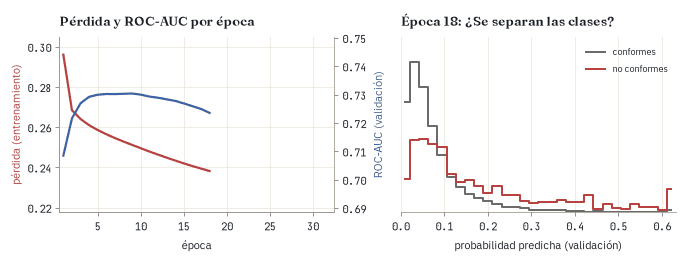
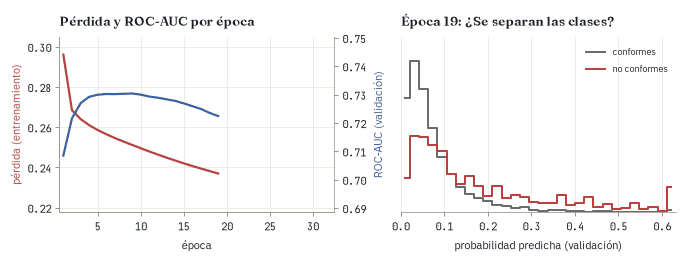
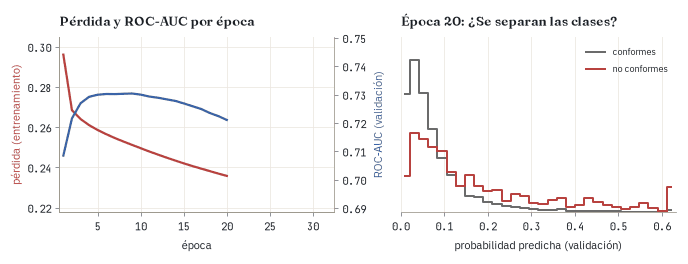
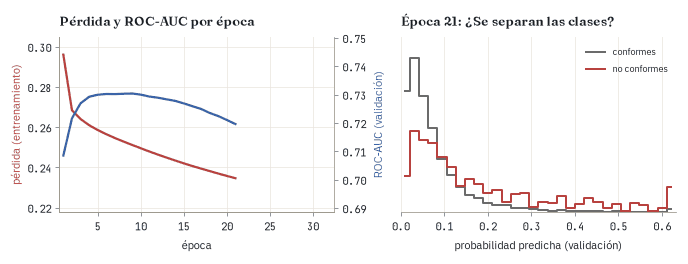
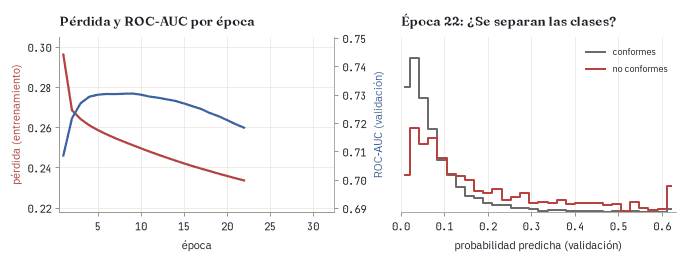
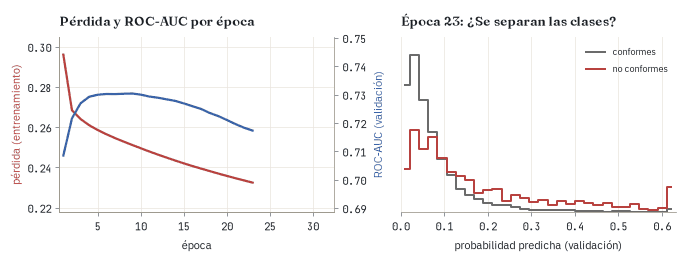
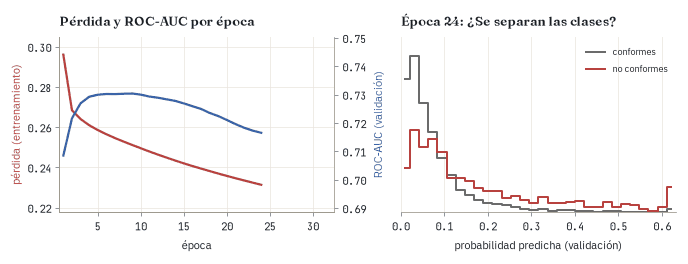
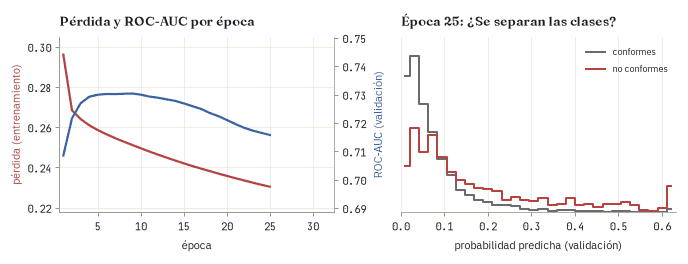
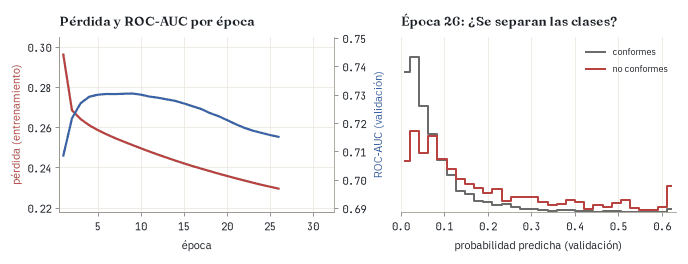
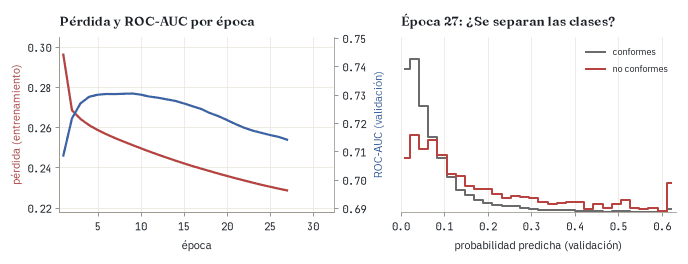
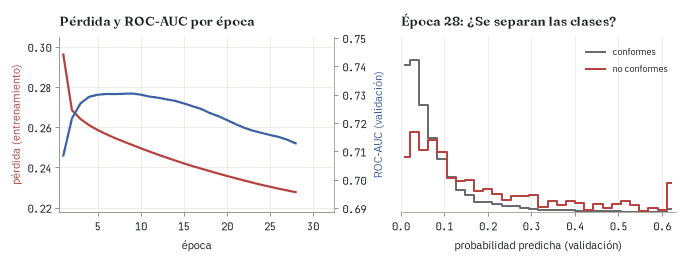
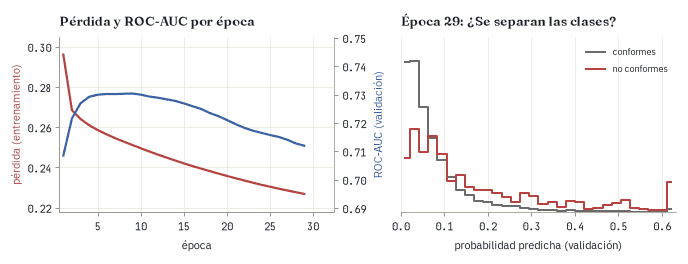
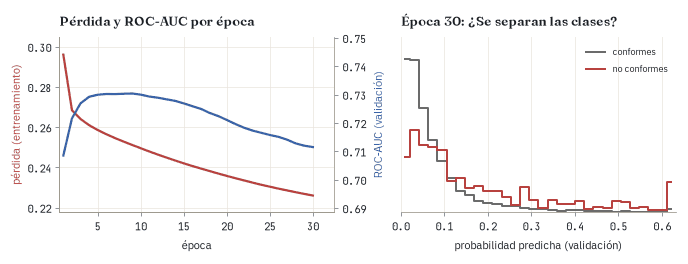
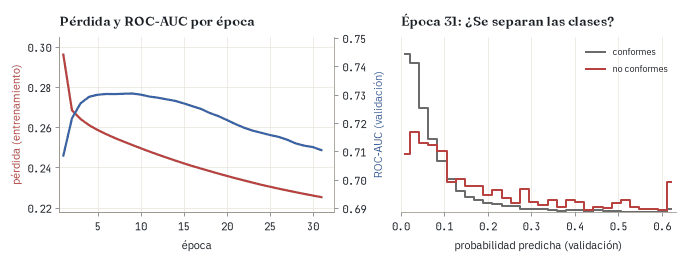
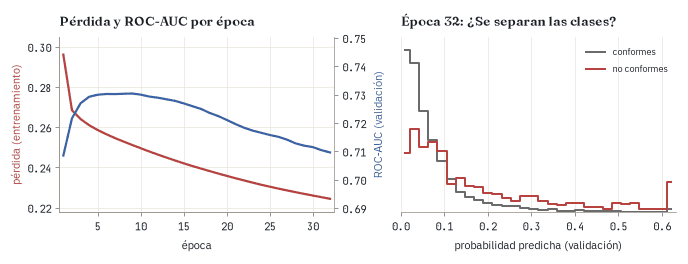

In [11]:
p = c.paneles   # arreglos de la red que calculó la sección anterior
mostrar(g.animacion_red(p.red_perdida, p.red_auc, p.red_histogramas, p.red_bordes))

Le dimos varias vueltas a si una red más grande o con menos penalización ordenaría mejor. El panel reentrena la red
en vivo con otro tamaño de capa oculta o con otro ${\color{#3B64A8}{\alpha}}$ (necesita el núcleo en marcha):

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

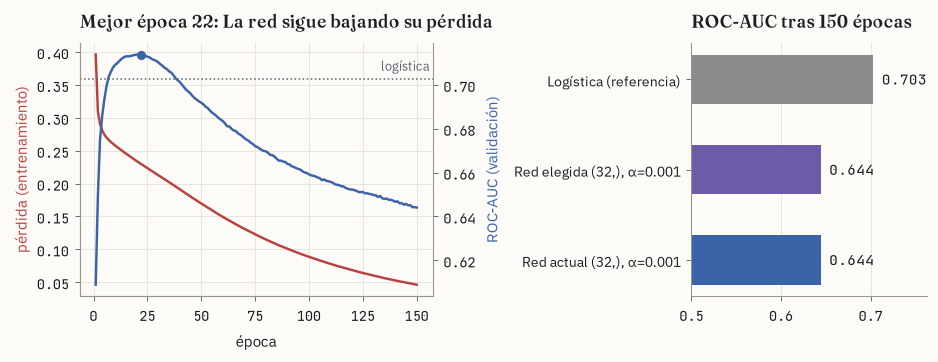

In [12]:
from proyecto.reporte import interactivo as ui

mostrar(ui.panel_red(c.paneles))   # capas ocultas y α: pérdida, ROC-AUC y la logística de referencia

## 3. Nivel 2: Cribado de la tubería con un arreglo L16 de Taguchi

Los factores son el modelo, el escalado, el grupo de variables, qué hacer con el desbalance (sobremuestrear la
clase minoritaria, solo al ajustar), la selección de variables y la codificación. Las 128 combinaciones se reducen
a 16 con la misma asignación de columnas de la etapa 04. La respuesta es el ROC-AUC de cada bloque, resumido con la
razón señal/ruido de Taguchi en la versión "mayor es mejor", que castiga a la vez un ROC-AUC bajo y uno que cambia
mucho entre bloques:

$$\frac{S}{N} = -10\,\log_{10}\Big(\frac{1}{B}\sum_{b=1}^{B}\frac{1}{{\color{#3B64A8}{\mathrm{AUC}_b^2}}}\Big)$$

In [13]:
clasificacion.diseno(c).mostrar()

Corrida,modelo,escalado,grupo,desbalance,seleccion,codificacion
1,knn,estandar,base,ninguna,ninguna,one_hot
2,knn,estandar,ampliado,sobremuestreo,26,ordinal
3,knn,minmax,base,ninguna,26,ordinal
4,knn,minmax,ampliado,sobremuestreo,ninguna,one_hot
5,logistica,estandar,base,sobremuestreo,ninguna,ordinal
6,logistica,estandar,ampliado,ninguna,26,one_hot
7,logistica,minmax,base,sobremuestreo,26,one_hot
8,logistica,minmax,ampliado,ninguna,ninguna,ordinal
9,arbol,estandar,base,sobremuestreo,26,one_hot
10,arbol,estandar,ampliado,ninguna,ninguna,ordinal


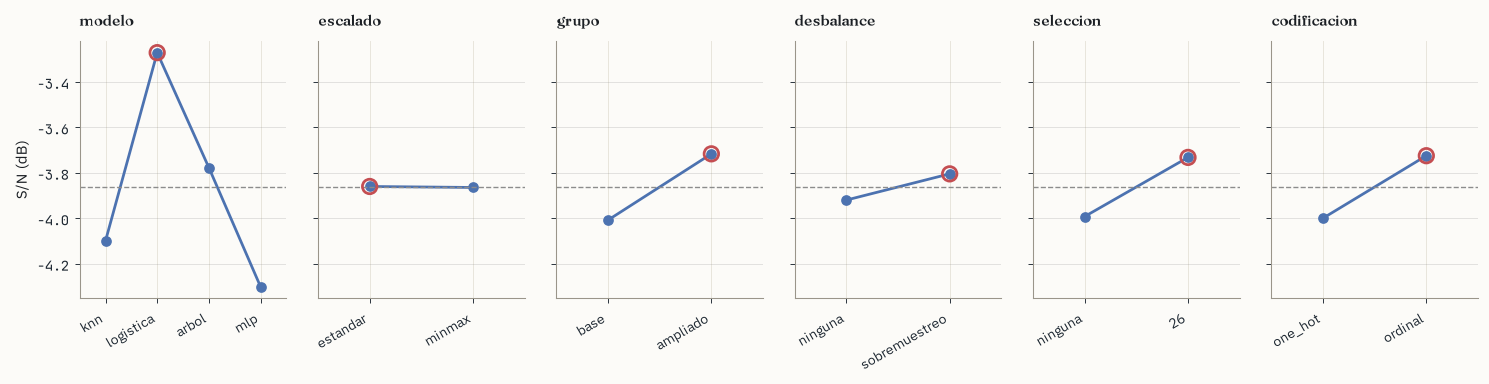

In [14]:
clasificacion.corridas_l16(c).mostrar()

### Comprobación aparte: Modelo y sobremuestreo

Sospechábamos que el sobremuestreo no le pega igual a todos los modelos. En el perceptrón con parada temprana las
copias de un mismo no conforme pueden caer a la vez en su entrenamiento y en su validación interna, y en todos los
modelos igualar las clases hace que las probabilidades dejen de estar calibradas. Como en el L16 esta interacción
queda mezclada, repetimos cada modelo didáctico con sobremuestreo.

In [15]:
clasificacion.sobremuestreo(c).mostrar()

Modelo,AUC sin,AUC con,Δ AUC,Brier sin,Brier con,Prob. media sin,Prob. media con
KNN,0.634,0.615,-0.019,0.081,0.257,0.088,0.383
Regresión logística,0.702,0.699,-0.003,0.075,0.227,0.095,0.451
Árbol podado,0.639,0.597,-0.041,0.085,0.200,0.098,0.243
Perceptrón multicapa,0.692,0.612,-0.080,0.076,0.176,0.097,0.193


### Corrida de confirmación

El óptimo aditivo no tiene por qué estar entre las 16 corridas así que lo corremos aparte y comparamos su S/N con
la predicha.

In [16]:
clasificacion.confirmacion(c).mostrar()

## 4. Nivel 3: Afinamiento de hiperparámetros

Igual que en la etapa 04 pasan la configuración de mayor S/N observada y la segunda mejor familia de modelos. Las
rejillas las recorremos con `GridSearchCV` en los mismos bloques y con el ROC-AUC como métrica.

In [17]:
clasificacion.afinamiento(c).mostrar()

### Los hiperparámetros a mano

Antes de seguir quisimos ver qué hace cada hiperparámetro de los modelos del curso. En KNN el número de vecinos
${\color{#6E5BA8}{k}}$ decide cuánto se promedia y en el árbol ${\color{#6E5BA8}{\alpha}}$ decide cuánto se poda.
Los dos paneles reentrenan en vivo sobre una submuestra fija.

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

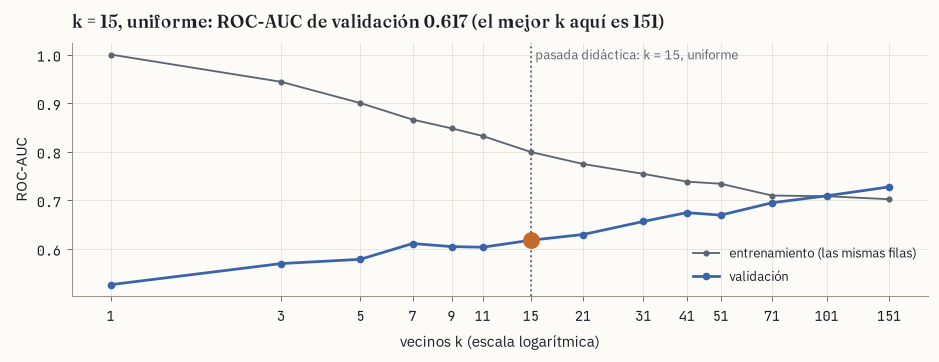

In [18]:
mostrar(ui.panel_knn(c.paneles))     # vecinos k: sobreajuste con k pequeño, subajuste con k grande

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

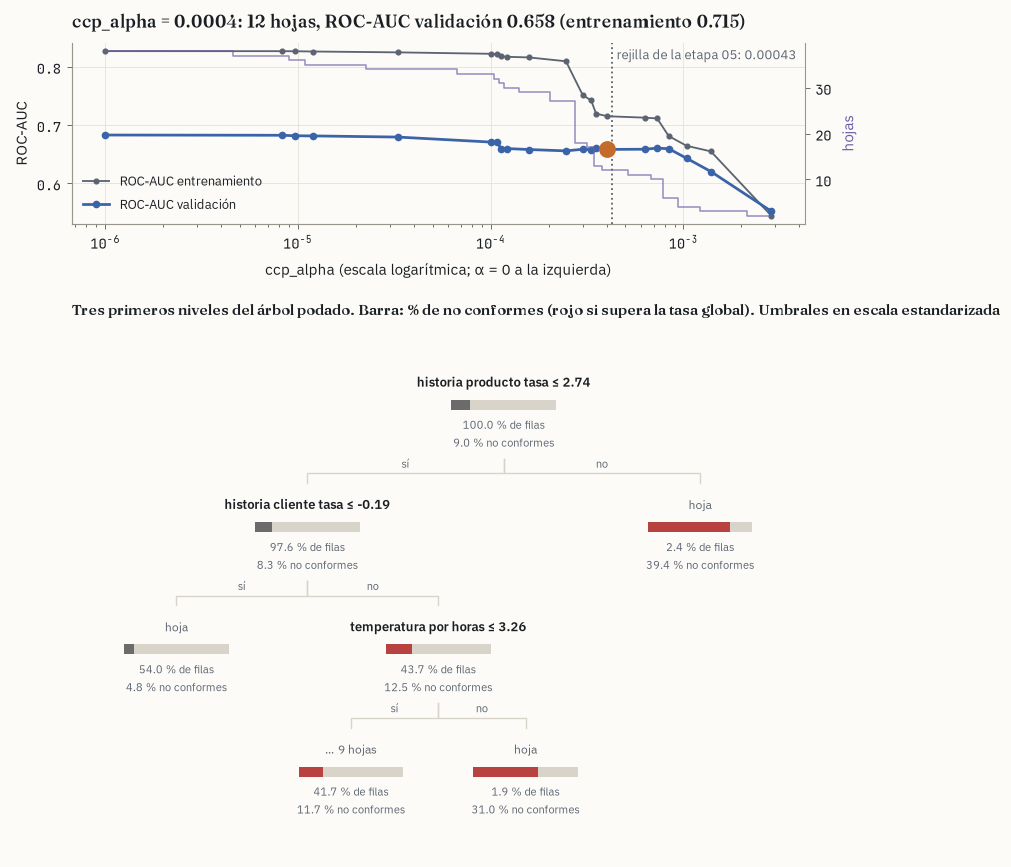

In [19]:
mostrar(ui.panel_arbol(c.paneles))   # poda ccp_alpha: hojas, ROC-AUC y el árbol que queda

### Evaluación única en validación

La regla la fijamos antes de mirar: Gana el mayor ROC-AUC de validación y, si la diferencia es menor que 0.005,
el más sencillo (regresión logística, árbol, KNN, perceptrón).

In [20]:
clasificacion.evaluacion_validacion(c).mostrar()

Candidato,ROC-AUC,AUC inf.,AUC sup.,Precisión media,Brier
Regresión logística,0.7243,0.7008,0.7482,0.2582,0.2269
Árbol de decisión,0.6969,0.6721,0.7201,0.2035,0.2332
Dummy (proporción),0.5000,,,0.0893,0.0814


## 5. Calibración

El umbral teórico y la parte B suponen que una probabilidad de 0.2 quiere decir que unas veinte de cada cien
muestras así salen no conformes. La versión calibrada usa `CalibratedClassifierCV` con el método sigmoide (el de
Platt, que solo ajusta dos parámetros y por eso aguanta pocos no conformes por tramo) y los mismos bloques
temporales como `cv`. La regla es usar la calibrada si la tubería sobremuestrea o si su Brier de validación es
menor.

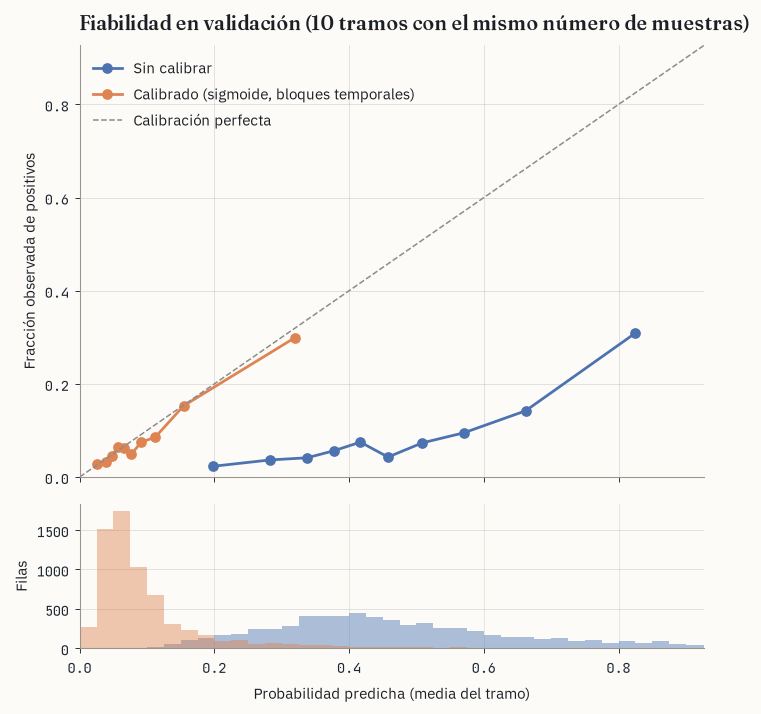

In [21]:
clasificacion.calibracion(c).mostrar()

## 6. Umbral por costo en validación

La regla de decisión cabe en una línea: Se alerta si el riesgo pasa el umbral y cada umbral deja sus falsas
alarmas, sus omisiones y su costo. Así se ve con el umbral teórico:

In [22]:
from proyecto.base import config
from proyecto.reporte.html import tarjetas

alerta = c.p_val >= c.umbral_teorico            # alertar cuando el riesgo pasa el umbral teórico
fp = int((alerta & (c.y_val == 0)).sum())       # falsas alarmas: conformes con alerta
fn = int((~alerta & (c.y_val == 1)).sum())      # no conformes sin alerta
cifras = [{"titulo": "Falsas alarmas (FP)", "valor": fp}, {"titulo": "Sin alerta (FN)", "valor": fn, "color": "rojo"},
          {"titulo": "Costo", "valor": config.COSTO_FP * fp + config.COSTO_FN * fn, "color": "naranja"}]
mostrar(tarjetas(cifras, titulo=f"Con el umbral teórico t = {c.umbral_teorico:.3f} en validación"))

Después recorremos umbrales de 0.02 a 0.50 (más el teórico) y elegimos el de menor costo. Si hay empate gana el más
alto. Al lado del costo van siempre la precisión, el recall y las alertas por semana, que es la carga que de verdad
recibe el laboratorio.

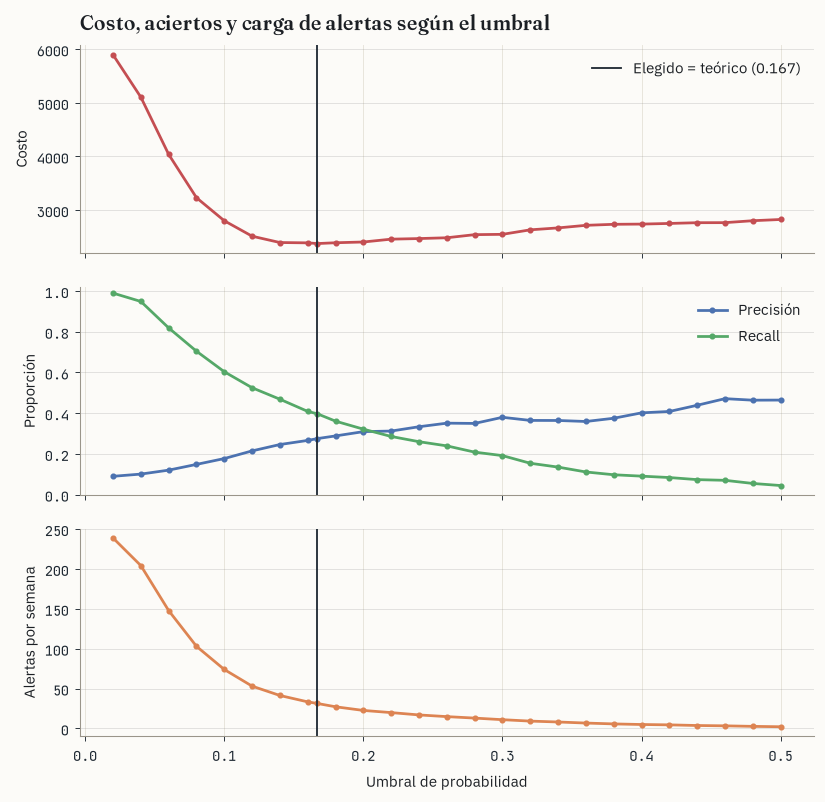

Umbral,Alertas,Alertas por semana,Precisión,Recall,FP,FN,Costo
0.020,6446,238.7,0.090,0.990,5867,6,5897
0.040,5511,204.1,0.101,0.949,4956,30,5106
0.060,3988,147.7,0.120,0.819,3509,106,4039
0.080,2778,102.9,0.148,0.704,2366,173,3231
0.100,1994,73.9,0.177,0.603,1641,232,2801
0.120,1430,53.0,0.215,0.525,1123,278,2513
0.140,1114,41.3,0.246,0.468,840,311,2395
0.160,898,33.3,0.266,0.409,659,346,2389
0.167,843,31.2,0.275,0.397,611,353,2376
0.180,732,27.1,0.288,0.361,521,374,2391

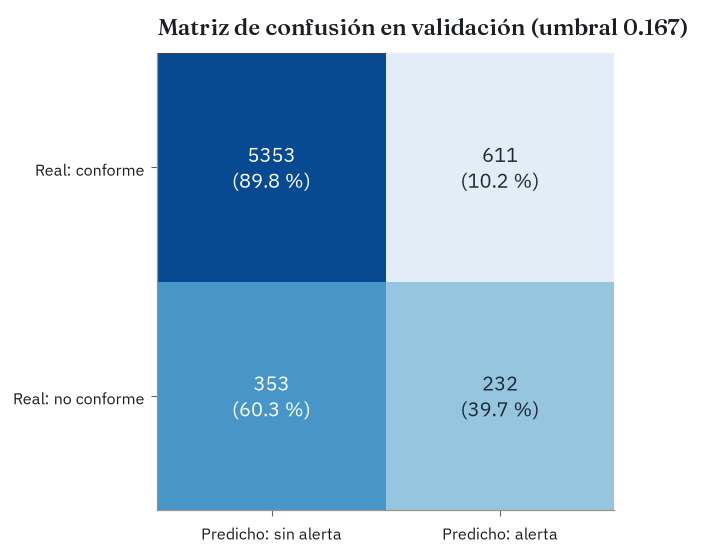

In [23]:
clasificacion.umbral_por_costo(c).mostrar()

La animación recorre los mismos umbrales. A la izquierda la línea naranja corta las probabilidades de validación y a
la derecha se ve cómo se mueve el costo:


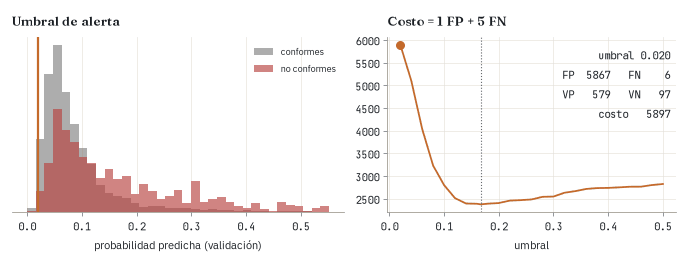
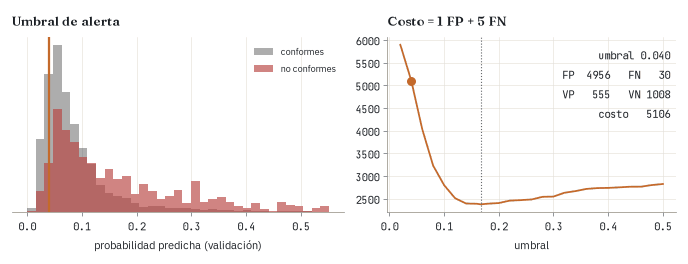
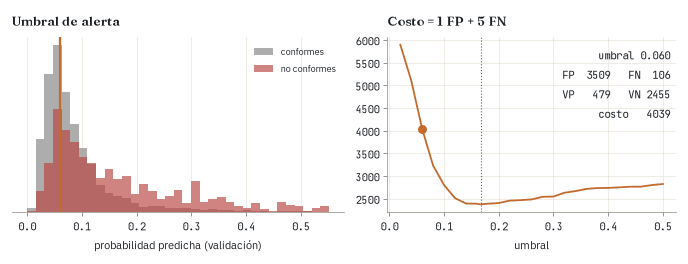
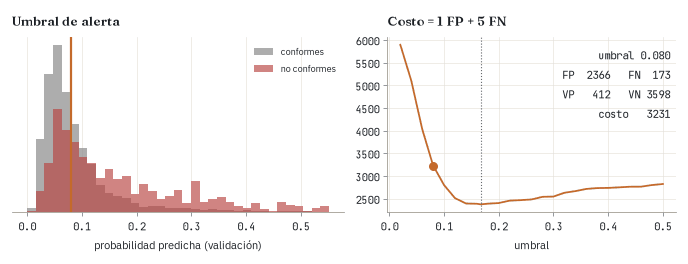
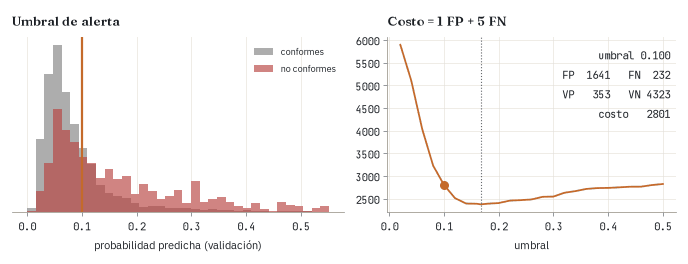
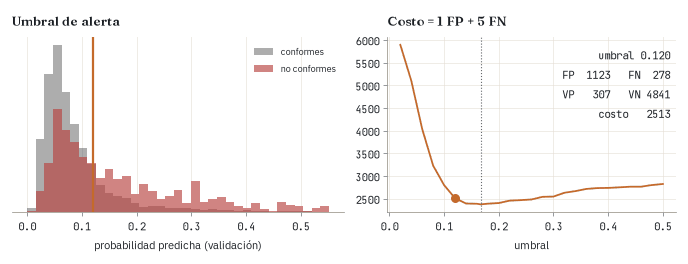
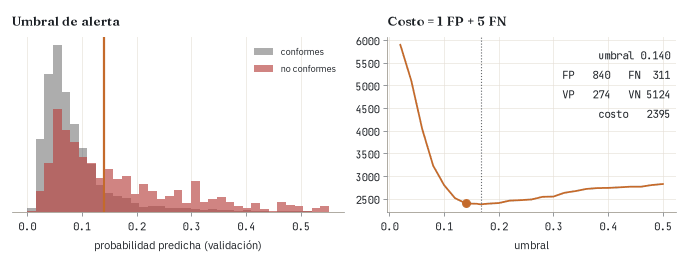
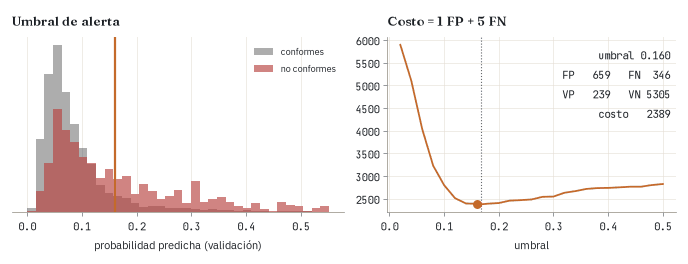
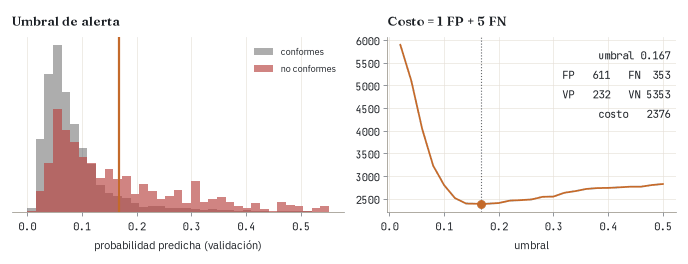
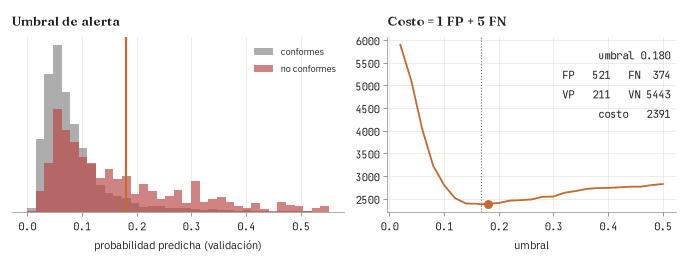
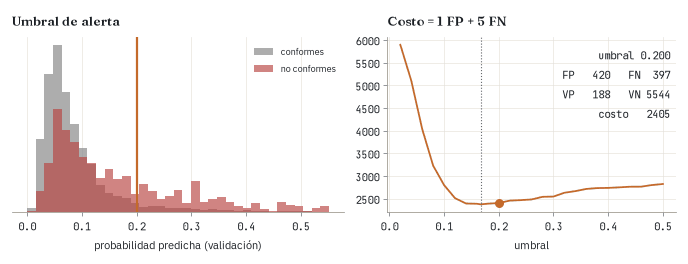
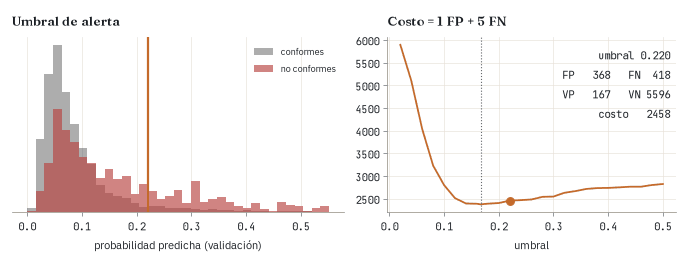
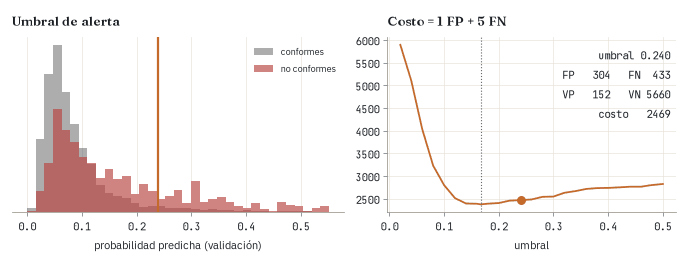
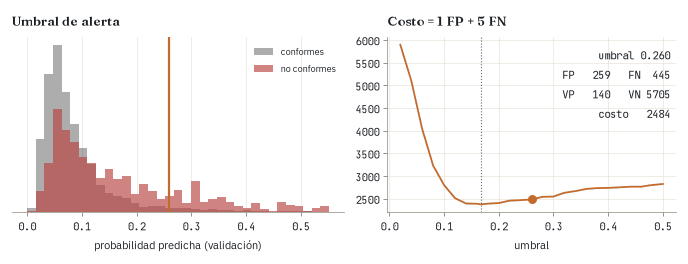
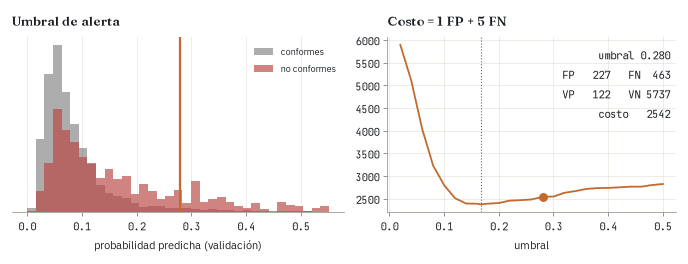
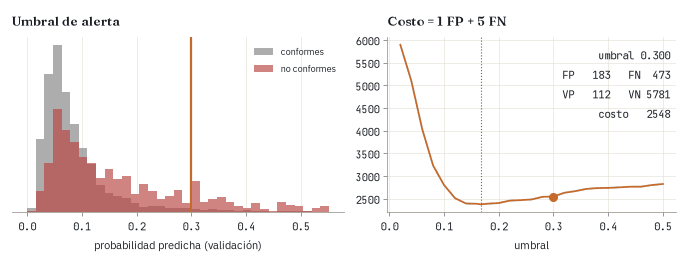
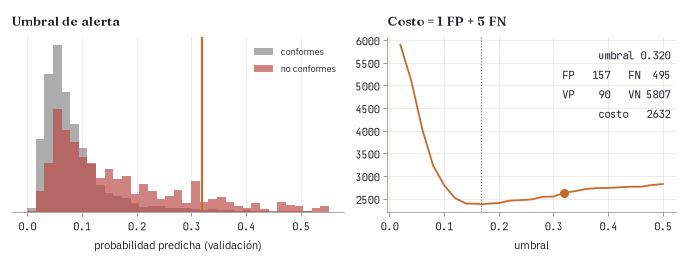
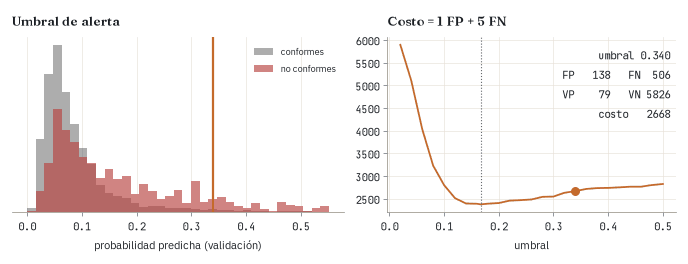
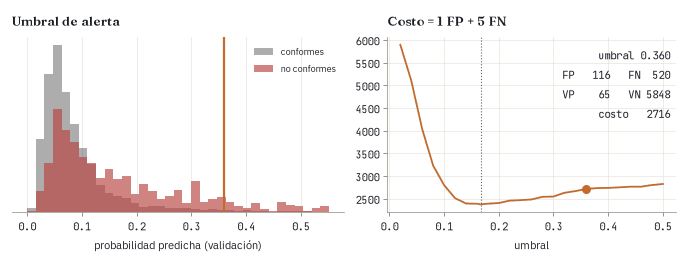
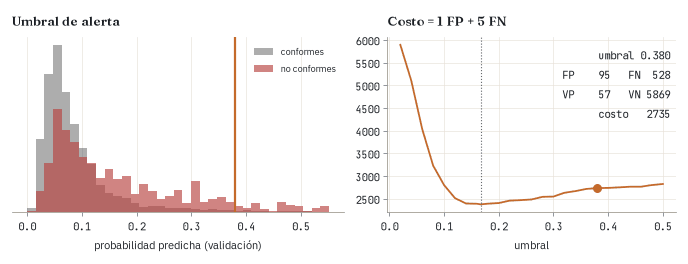
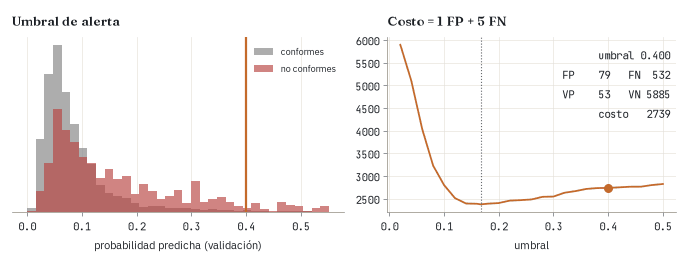
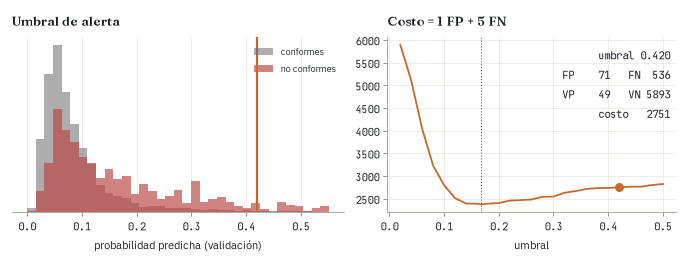
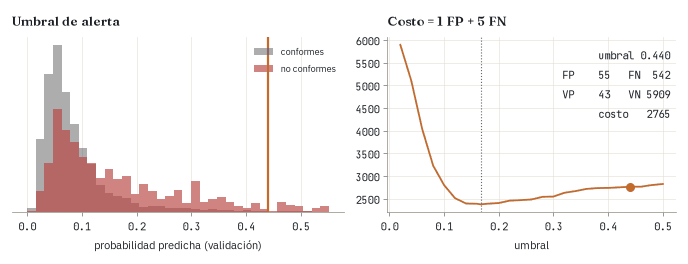
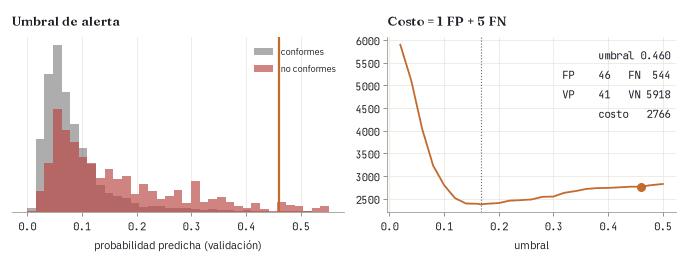
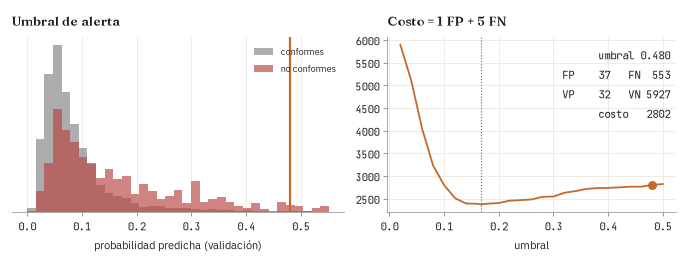
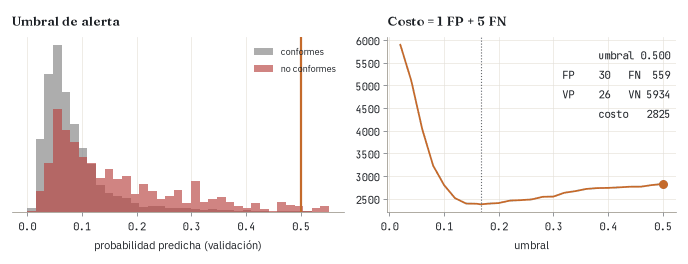

In [24]:
umbrales = list(c.tabla_umbral["Umbral"])   # el mismo recorrido de la tabla
mostrar(g.animacion_umbral(c.p_val, c.y_val, umbrales, config.COSTO_FP, config.COSTO_FN, c.umbral))

En el panel se puede mover el umbral a mano o cambiar cuánto más cara es una omisión que una falsa alarma, para ver
dónde quedaría el óptimo:

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

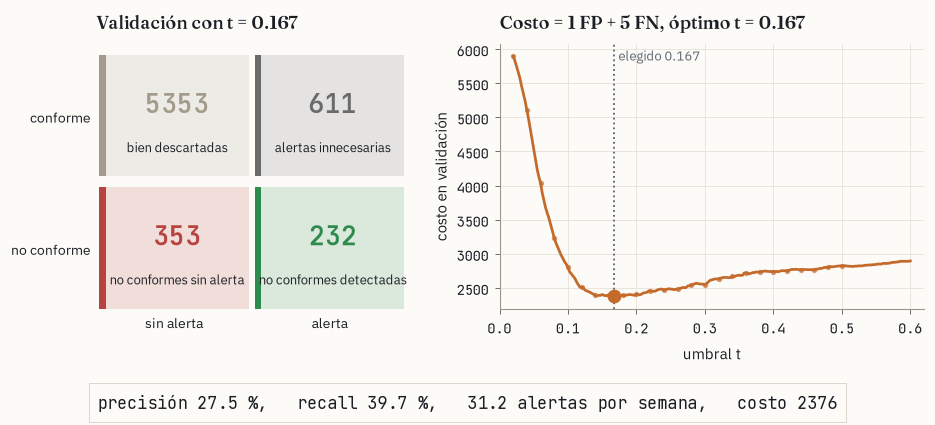

In [25]:
mostrar(ui.panel_umbral(c.paneles))   # umbral y razón de costos: precisión, recall, alertas por semana y costo

## 7. Congelamiento del modelo

Los hiperparámetros, la configuración, la calibración y el umbral quedan fijos y el modelo se reajusta con
entrenamiento y validación. Si va calibrado, la calibración usa los bloques temporales de todo el desarrollo.

In [26]:
clasificacion.congelar(c).mostrar()

Antes de cerrar la parte A volvimos al L16 para ver qué habría pasado con otra combinación de factores. El panel lo
responde con lo que guardamos de las 16 corridas, sin volver a correr nada:

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

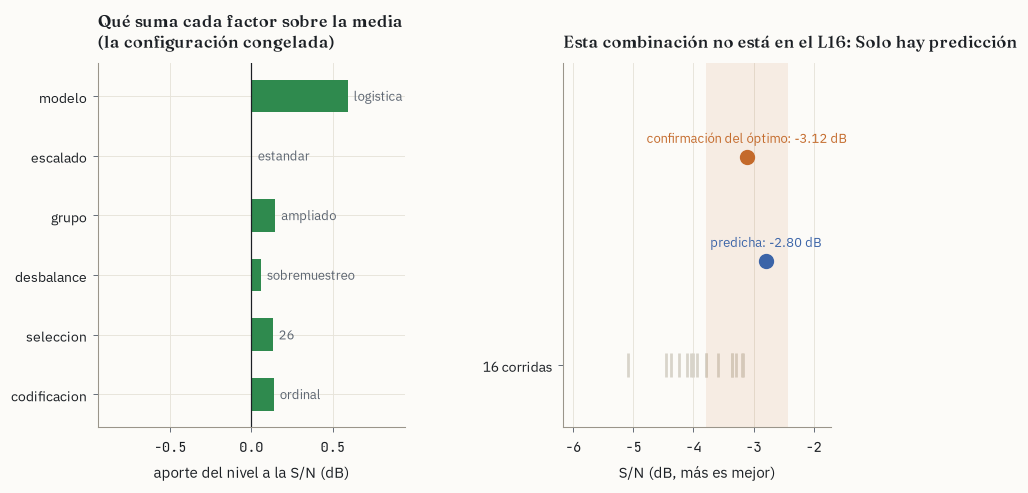

In [27]:
from proyecto.etapas.comun import legible

congelada = {f: legible(v) for f, v in c.configuracion_final.items()}   # niveles de la configuración congelada
mostrar(ui.panel_taguchi(c.taguchi, congelada, rotulo="Clasificación", etapa="05"))

## Parte B: Bayes, o qué tan probable es que un positivo sea falso

## 8. La idea en palabras y en fórmulas

Un ensayo se describe con dos números que salen de sus controles de calidad:

a. **Sensibilidad** ${\color{#2F8A4E}{S}}$. La fracción de muestras contaminadas que dan positivo. Se mide con
   controles positivos.

b. **Especificidad** $E$. La fracción de muestras limpias que dan negativo. Se mide con controles negativos.

Con la probabilidad previa de contaminación ${\color{#3B64A8}{p}}$ el teorema de Bayes da el **valor predictivo
positivo** (VPP), la fracción de positivos que son verdaderos. Arriba va la masa de
${\color{#2F8A4E}{\text{verdaderos positivos}}}$ y abajo se le suma la de
${\color{#B8423F}{\text{falsos positivos}}}$:

$$\mathrm{VPP} = P(\text{contaminada} \mid +) = \frac{{\color{#2F8A4E}{S\,{\color{#3B64A8}{p}}}}}{{\color{#2F8A4E}{S\,{\color{#3B64A8}{p}}}}
+ {\color{#B8423F}{(1-E)(1-{\color{#3B64A8}{p}})}}}
\qquad\qquad P(\text{falso positivo} \mid +) = 1 - \mathrm{VPP}$$

Con una prevalencia baja el término rojo pesa mucho aunque $1 - E$ sea pequeño. Por ejemplo, con E = 0.98,
p = 0.05 y S = 0.95 más de una de cada cuatro alarmas es falsa. El video lo cuenta con un árbol de mil muestras
del ensayo de esterilidad:


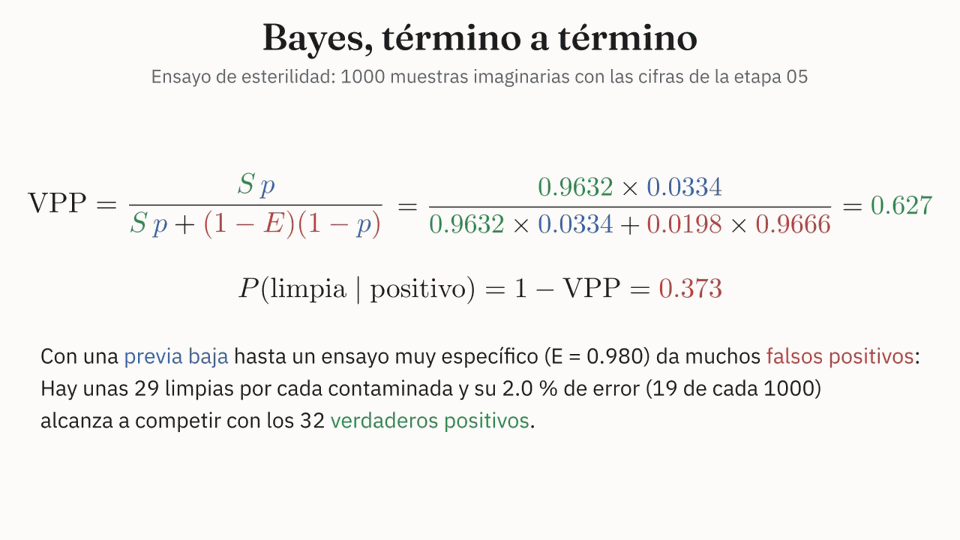

In [28]:
mostrar(g.video("bayes"))   # Manim: el árbol de 1000 muestras se vuelve la fórmula

La prevalencia no se observa. Lo que se observa es la tasa de positivos y despejando ${\color{#3B64A8}{p}}$ de
esa tasa (que mezcla verdaderos y falsos positivos) sale la corrección de Rogan y Gladen. Si una muestra se
reensaya, la probabilidad después del primer resultado hace de previa para el segundo.

## 9. Sensibilidad y especificidad de cada ensayo

Solo usamos controles anteriores al periodo de prueba y los intervalos son de Wilson al 95 %, que se portan bien
aunque la proporción esté cerca de uno.

In [29]:
clasificacion.sensibilidad_especificidad(c).mostrar()

Ensayo,Controles +,Sensibilidad,Sens. inf.,Sens. sup.,Controles −,Especificidad,Espec. inf.,Espec. sup.
Pseudomonas aeruginosa,1468,0.920,0.905,0.932,1468,0.986,0.978,0.991
Salmonella spp.,1468,0.897,0.881,0.912,1468,0.995,0.990,0.998
Staphylococcus aureus,1468,0.931,0.917,0.943,1468,0.990,0.983,0.994
coliformes y E. coli,1468,0.937,0.924,0.949,1468,0.980,0.972,0.986
esterilidad,1468,0.963,0.952,0.972,1468,0.980,0.972,0.986
mesófilos aerobios,1468,0.966,0.955,0.974,1468,0.977,0.968,0.983
mohos y levaduras,1468,0.950,0.938,0.960,1468,0.976,0.967,0.983


## 10. VPP por ensayo

La tasa de positivos sale de las muestras aceptadas del desarrollo. Para la incertidumbre sorteamos miles de veces
la sensibilidad, la especificidad y la tasa de positivos de sus distribuciones Beta (una previa uniforme más los
conteos de cada una) con la semilla del proyecto y calculamos el VPP en cada sorteo.

Ensayo,Muestras,Positivos,Tasa de positivos,Sens.,Espec.,Prevalencia corregida,VPP,VPP inf.,VPP sup.,P(falso positivo)
Pseudomonas aeruginosa,2869,195,0.068,0.920,0.986,0.059,0.802,0.685,0.875,0.198
Salmonella spp.,520,23,0.044,0.897,0.995,0.044,0.897,0.761,0.956,0.103
Staphylococcus aureus,2684,100,0.037,0.931,0.990,0.029,0.734,0.543,0.842,0.266
coliformes y E. coli,4773,414,0.087,0.937,0.980,0.073,0.789,0.687,0.855,0.211
esterilidad,1366,70,0.051,0.963,0.980,0.033,0.627,0.428,0.759,0.373
mesófilos aerobios,10625,1071,0.101,0.966,0.977,0.082,0.789,0.702,0.849,0.211
mohos y levaduras,6175,632,0.102,0.950,0.976,0.085,0.787,0.701,0.850,0.213


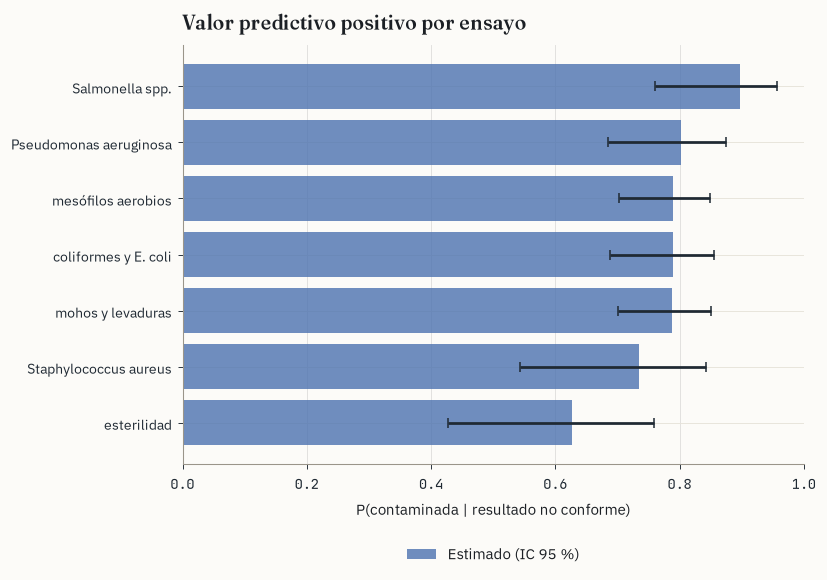

In [30]:
clasificacion.vpp_por_ensayo(c).mostrar()

La misma fórmula sirve para cualquier previa. Con `bayes.valor_predictivo_positivo` sobre una rejilla de previas
sale la curva de cada ensayo y el punto es donde queda cada uno con su prevalencia corregida:

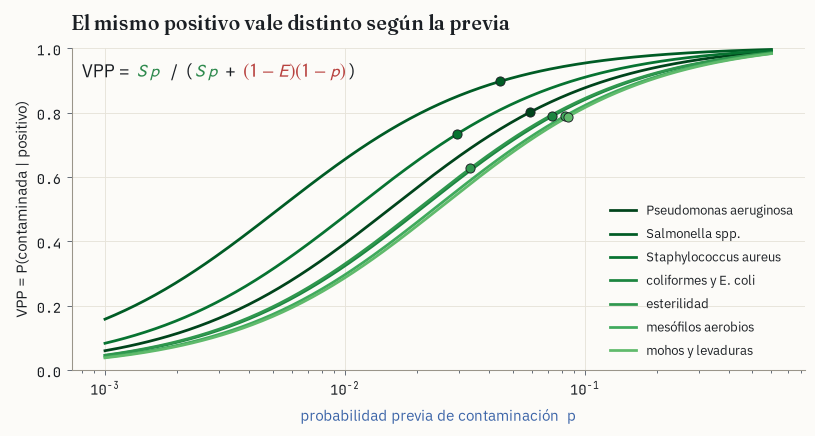

In [31]:
import numpy as np
from proyecto.evaluacion import bayes

t = c.tabla_vpp                                     # sensibilidad, especificidad y VPP de cada ensayo
previas = np.geomspace(1e-3, 0.6, 200)[:, None]     # rejilla de previas para dibujar
vpp = bayes.valor_predictivo_positivo(previas, t["sensibilidad"].to_numpy(), t["especificidad"].to_numpy())
marcas = dict(zip(t["ensayo"], zip(t["prevalencia_corregida"], t["vpp"])))
mostrar_figura(g.figura_vpp(previas[:, 0], vpp, t["ensayo"].tolist(), marcas))

Panel interactivo: Ejecute la celda con el núcleo en marcha para mover los controles.

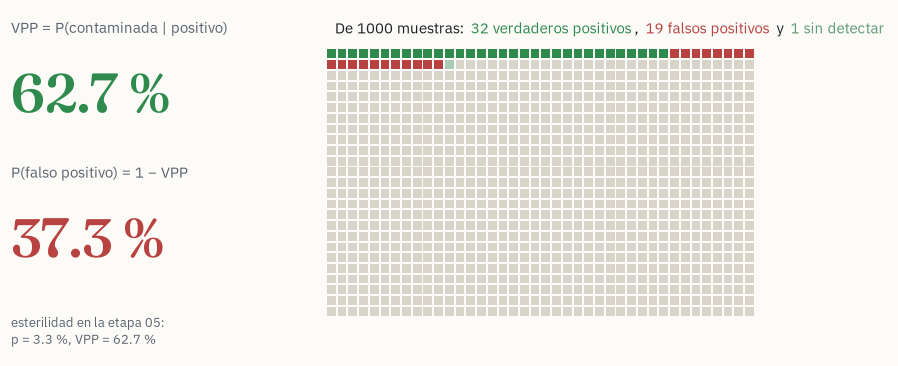

In [32]:
mostrar(ui.panel_bayes(c.paneles))   # previa, sensibilidad y especificidad: VPP y falsos positivos de cada mil

## 11. VPP por muestra: La previa que aporta el clasificador

El clasificador estima p(x), la tasa de positivos que se espera para muestras como x. Si aplicamos Rogan y Gladen
muestra a muestra sale la previa π(x) y con ella VPP(x) = S π(x) / p(x). Usamos el modelo de la parte A ajustado
solo con entrenamiento, sobre las muestras de validación. Que π(x) = 0 quiere decir que el positivo se explica
entero por el error del ensayo.

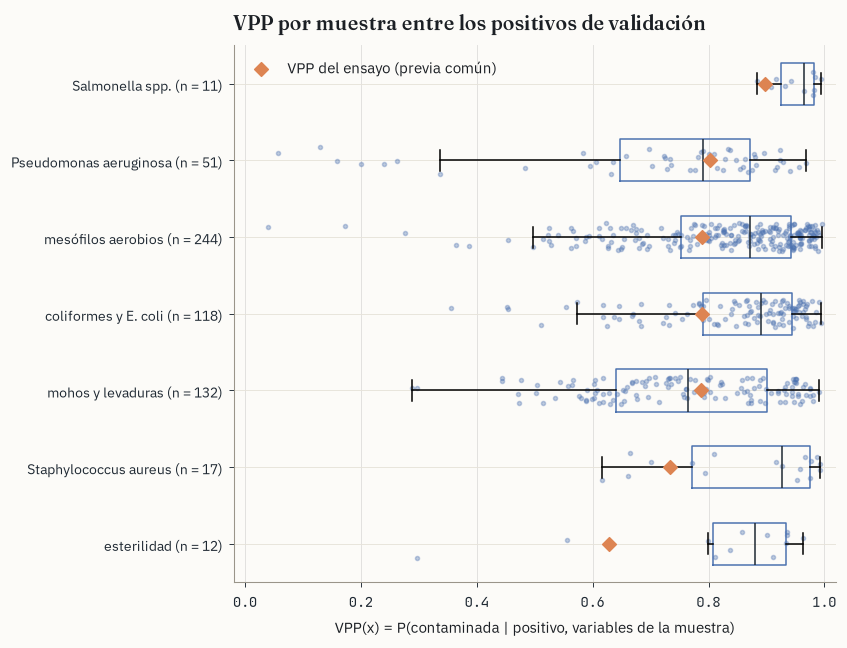

Ensayo,Positivos,VPP(x) medio,Percentil 10,Mediana,Percentil 90
Pseudomonas aeruginosa,51.000,0.715,0.262,0.791,0.923
Salmonella spp.,11.000,0.952,0.908,0.965,0.984
Staphylococcus aureus,17.000,0.862,0.663,0.926,0.989
coliformes y E. coli,118.000,0.849,0.661,0.890,0.967
esterilidad,12.000,0.811,0.581,0.879,0.935
mesófilos aerobios,244.000,0.826,0.623,0.871,0.973
mohos y levaduras,132.000,0.761,0.565,0.765,0.951


In [33]:
clasificacion.vpp_por_muestra(c).mostrar()

## 12. Lo que pasa después del reensayo

Con dos positivos la confianza sube y con un positivo y un negativo baja, si suponemos que los dos resultados son
independientes dada la condición real de la muestra. El modelo también predice qué fracción de los reensayos
debería salir conforme, P(− | + inicial) = VPP (1 − S) + (1 − VPP) E, que sí podemos comparar con lo observado.

In [34]:
clasificacion.reensayo(c).mostrar()

Ensayo,VPP (un +),"Posterior (+, +)","Posterior (+, −)",Reensayados,Fracción reensayada,Reensayo conforme esperado,Reensayo conforme observado
Pseudomonas aeruginosa,0.802,0.996,0.248,176,0.903,0.260,0.284
Salmonella spp.,0.897,0.999,0.474,21,0.913,0.195,0.429
Staphylococcus aureus,0.734,0.996,0.161,89,0.890,0.314,0.337
coliformes y E. coli,0.789,0.994,0.193,363,0.877,0.256,0.231
esterilidad,0.627,0.988,0.059,62,0.886,0.388,0.484
mesófilos aerobios,0.789,0.994,0.115,927,0.866,0.233,0.227
mohos y levaduras,0.787,0.993,0.158,548,0.867,0.247,0.332


## 13. Auditoría de la simulación

Solo porque los datos son simulados existe una verdad oculta (qué muestra estaba de verdad contaminada). Con datos
reales la única referencia es el reensayo, que también falla.

Ensayo,Sens. estimada,Sens. real,Espec. estimada,Espec. efectiva real,Prevalencia corregida,Prevalencia real,VPP estimado,VPP real,Dentro del IC
Pseudomonas aeruginosa,0.920,0.920,0.986,0.984,0.059,0.059,0.802,0.795,Sí
Salmonella spp.,0.897,0.900,0.995,0.992,0.044,0.033,0.897,0.739,No
Staphylococcus aureus,0.931,0.930,0.990,0.986,0.029,0.026,0.734,0.670,Sí
coliformes y E. coli,0.937,0.940,0.980,0.980,0.073,0.075,0.789,0.802,Sí
esterilidad,0.963,0.960,0.980,0.970,0.033,0.026,0.627,0.471,Sí
mesófilos aerobios,0.966,0.970,0.977,0.979,0.082,0.083,0.789,0.795,Sí
mohos y levaduras,0.950,0.950,0.976,0.970,0.085,0.076,0.787,0.696,No


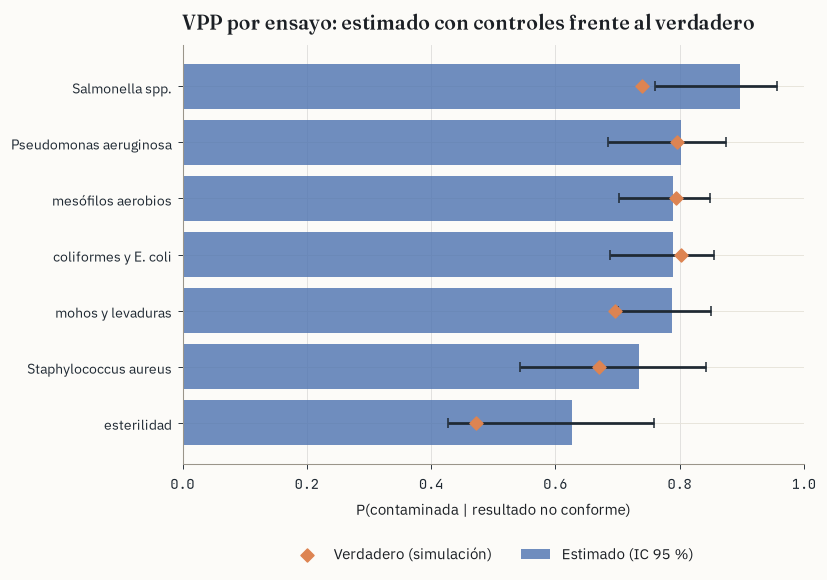

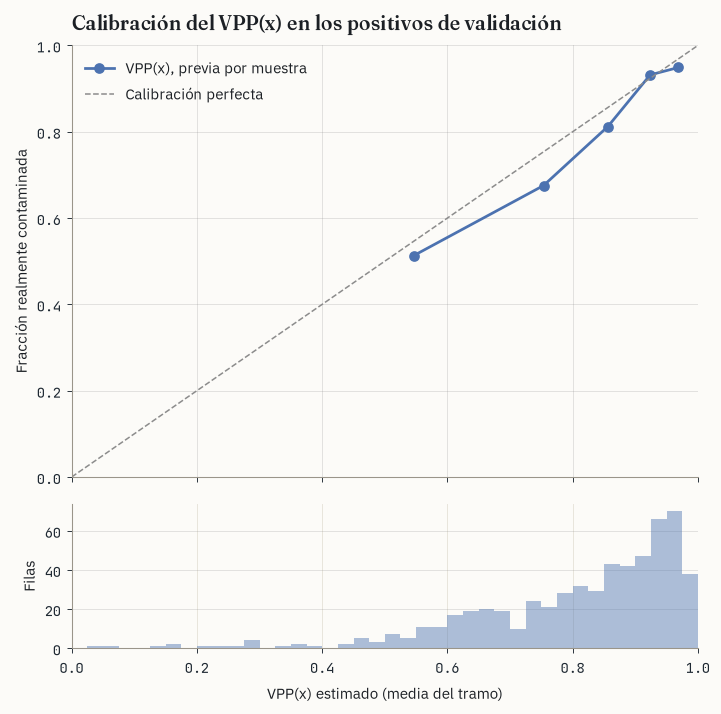

In [35]:
clasificacion.auditoria(c).mostrar()

## 14. Una regla simple para el reensayo

En la etapa 03 dejamos por fuera el análisis "falso positivo entre los no conformes" porque una sola variable, la
razón logarítmica entre el recuento y el límite, explicaba casi todo. Aquí leemos esa relación por tramos con los
no conformes reensayados del desarrollo.

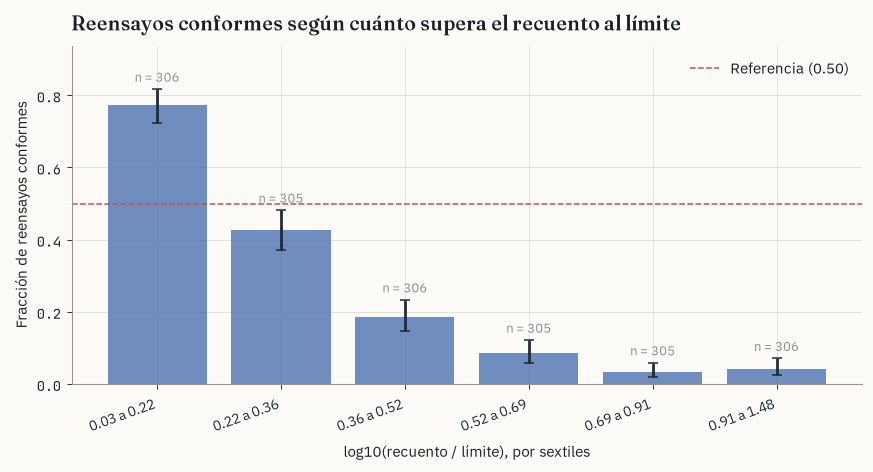

In [36]:
clasificacion.regla_reensayo(c).mostrar()

In [37]:
clasificacion.terminar(c)

← Anterior: [Etapa 04: Regresión](04_regresion.ipynb)<br>[Notebook completo](Proyecto_Final.ipynb)<br>Siguiente: [Etapa 06: Agrupamiento](06_agrupamiento.ipynb) →